# Clustering
## Step 00: Load dataset

In [18]:
import pandas as pd

df = pd.read_csv("../01 - DataPreparation/df_prepared.csv")

print("Shape:", df.shape)
df.info()
df.columns

Shape: (20573, 30)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20573 entries, 0 to 20572
Data columns (total 30 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   BGGId                   20573 non-null  int64  
 1   GameWeight              20573 non-null  float64
 2   MinPlayers              20573 non-null  int64  
 3   MaxPlayers              20573 non-null  int64  
 4   NumOwned                20573 non-null  int64  
 5   NumWant                 20573 non-null  int64  
 6   NumAlternates           20573 non-null  int64  
 7   NumExpansions           20573 non-null  int64  
 8   NumImplementations      20573 non-null  int64  
 9   IsReimplementation      20573 non-null  int64  
 10  Kickstarted             20573 non-null  int64  
 11  Cat:Thematic            20573 non-null  int64  
 12  Cat:Strategy            20573 non-null  int64  
 13  Cat:War                 20573 non-null  int64  
 14  Cat:Family         

Index(['BGGId', 'GameWeight', 'MinPlayers', 'MaxPlayers', 'NumOwned',
       'NumWant', 'NumAlternates', 'NumExpansions', 'NumImplementations',
       'IsReimplementation', 'Kickstarted', 'Cat:Thematic', 'Cat:Strategy',
       'Cat:War', 'Cat:Family', 'Cat:CGS', 'Cat:Abstract', 'Cat:Party',
       'Cat:Childrens', 'Rating', 'Age', 'AvgPlaytime', 'AgeRec',
       'NumOwned_log', 'NumAlternates_log', 'NumExpansions_log',
       'NumImplementations_log', 'NumWant_log', 'AvgPlaytime_log',
       'MaxPlayers_log'],
      dtype='object')

## Step 01: Select features for clustering (choose attributes)
For this analysis we selected the attributes that describe the charateristics of the boardgames. So: all binary category features + Age, Gameweigh, MinPlayers, MaxPlayers_log, AgeRec, AvgPlaytime_log.
We clipped the extremely heavy tailed data of MaxPlayers_log and AvgPlaytime_log at the 99.5th percentile.
We standardized the continuous variables and we also applied a Bin weight of 2.0 at the categoty features to have a better distance between binary data.

In [19]:
from sklearn.preprocessing import StandardScaler
import numpy as np

categoric_cols = [
    'Cat:Thematic','Cat:Strategy','Cat:War','Cat:Family',
    'Cat:CGS','Cat:Abstract','Cat:Party','Cat:Childrens'
]

continuous_cols = [
    'Age',
    'GameWeight',
    'MinPlayers',
    'MaxPlayers_log',
    'AgeRec',
    'AvgPlaytime_log'
]


df2 = df.copy()

# Extremely heavy tailed data is clipped at 99.5th percentile
for col in ['AvgPlaytime_log', 'MaxPlayers_log']:
    cap = df2[col].quantile(0.995)
    df2[col] = df2[col].clip(upper=cap)

scaler = StandardScaler()
X_cont = scaler.fit_transform(df2[continuous_cols].to_numpy())

# Bin weight controls the distance between binary data
BIN_WEIGHT = 2.0
X_bin = df2[categoric_cols].to_numpy() * BIN_WEIGHT

Xp = np.hstack([X_cont, X_bin])
print(Xp.shape)


(20573, 14)


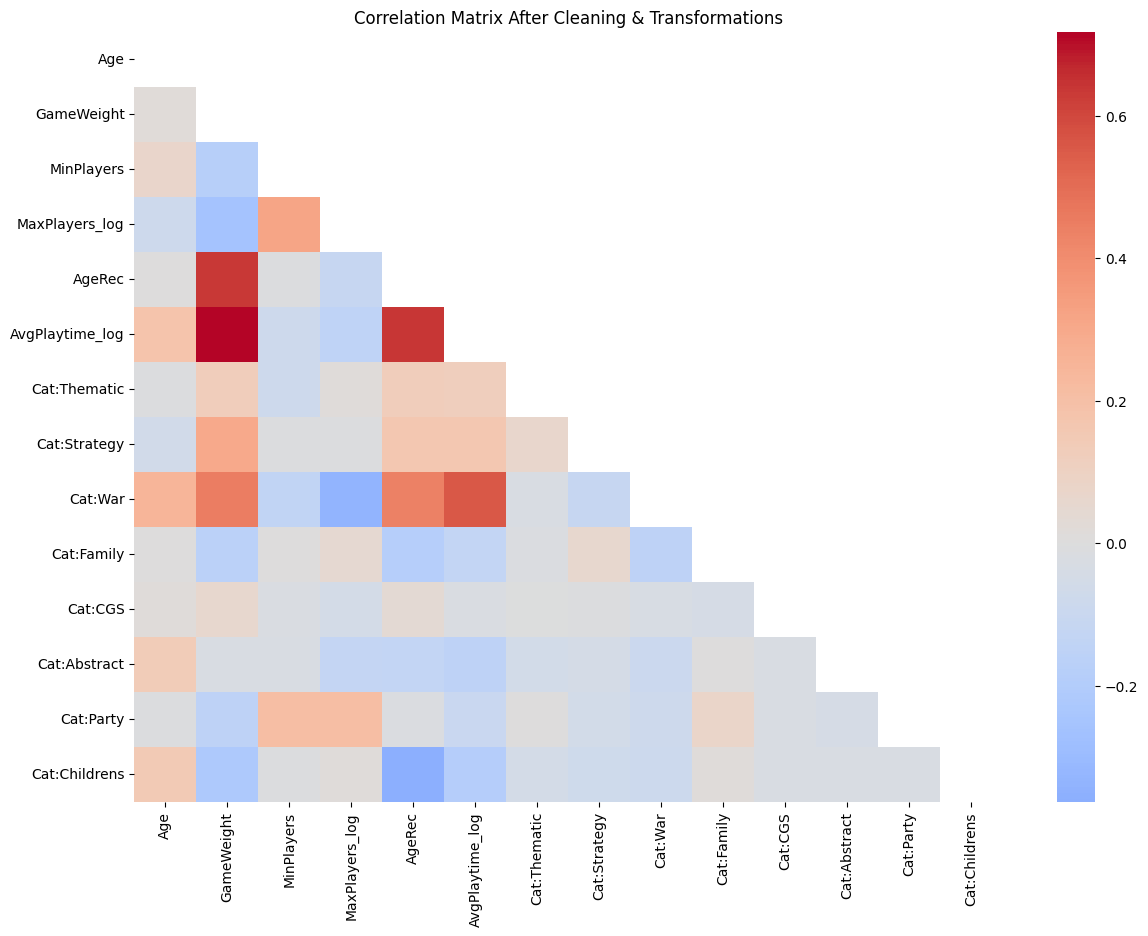

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns


test = df2[continuous_cols+categoric_cols].corr(numeric_only=True)

trimask = np.triu(np.ones_like(test, dtype=bool))

plt.figure(figsize=(14, 10))
sns.heatmap(test, cmap="coolwarm", center=0, mask=trimask)
plt.title("Correlation Matrix After Cleaning & Transformations")
plt.show()

### 1. K-Means

#### Evaluate K-Means for K = 2 to 30

To choose the right K we used Inertia (Elbow method) and the Silhouette Score.

In [21]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import pandas as pd

results = []

for k in range(2, 31):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=50)
    labels = kmeans.fit_predict(Xp)
    
    inertia = kmeans.inertia_
    sil = silhouette_score(Xp, labels)
    
    results.append((k, inertia, sil))
    print(f"{k},{inertia},{sil}")

# df_k = pd.DataFrame(results, columns=["K", "Inertia", "Silhouette"])
# print(df_k)

2,127816.08446096459,0.2323401492419233
3,113691.52422712557,0.18619018067954846
4,102109.6630624897,0.1938660751407088
5,94117.72192197302,0.19786968329389823
6,87887.7665023304,0.19364430685648534
7,82436.31005696229,0.202372306720838
8,77997.12317840818,0.21200384357142024
9,74606.78151295231,0.21552394988713472
10,71770.72267302188,0.18608930559176454
11,68963.2603634174,0.19341096610656952
12,66313.29844262425,0.18328376724665926
13,64085.94051295394,0.18360715722827833
14,62146.006770656044,0.18450784210133608
15,60429.43577642349,0.18007825349062478
16,59069.24386813304,0.19588510155347838
17,57207.93898533743,0.18183783879735824
18,55861.20466210798,0.1845294607309457
19,54624.6552750909,0.18957926657854693
20,53341.60257185594,0.18531219975038277
21,52295.56485246614,0.18389410062561998
22,51652.44752464379,0.19154559183109027
23,50416.4258250402,0.18629927382022057
24,49768.056917817376,0.18808077715431806
25,48717.2429852262,0.19150391256326793
26,48096.94522504533,0.1874944

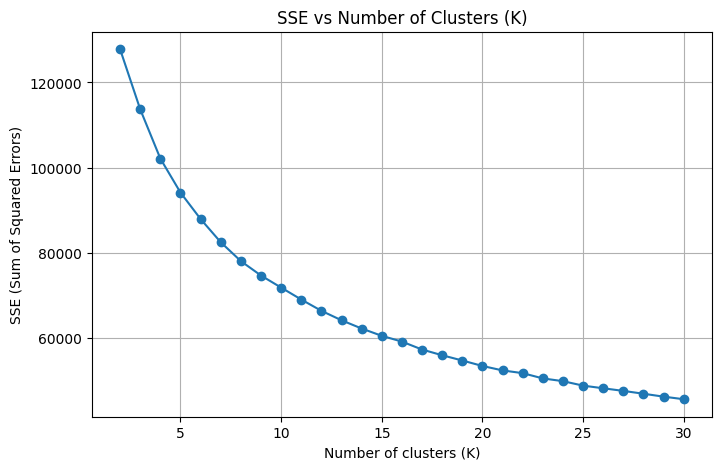

In [22]:
results_df = pd.DataFrame(results, columns=["K", "Inertia", "Silhouette"])

import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
plt.plot(results_df["K"], results_df["Inertia"], marker='o')
plt.title("SSE vs Number of Clusters (K)")
plt.xlabel("Number of clusters (K)")
plt.ylabel("SSE (Sum of Squared Errors)")
plt.grid(True)
plt.show()

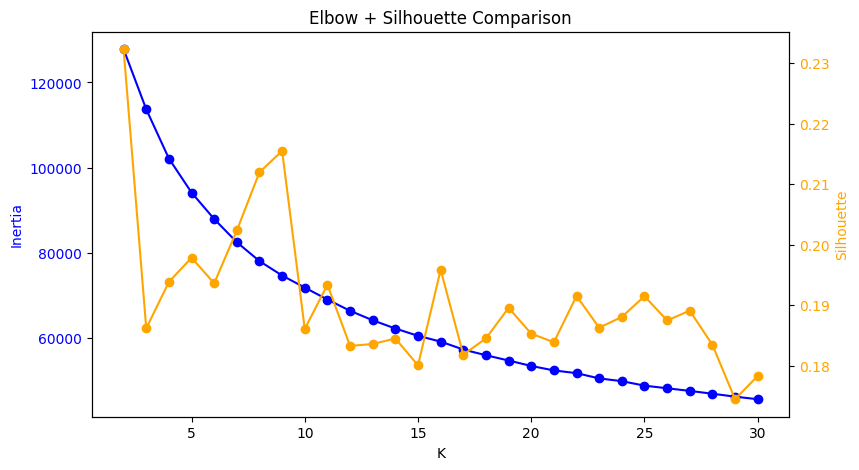

In [23]:
fig, ax1 = plt.subplots(figsize=(9,5))

ax1.set_xlabel("K")
ax1.set_ylabel("Inertia", color='blue')
ax1.plot(df_k["K"], df_k["Inertia"], marker='o', color='blue')
ax1.tick_params(axis='y', labelcolor='blue')

ax2 = ax1.twinx()
ax2.set_ylabel("Silhouette", color='orange')
ax2.plot(df_k["K"], df_k["Silhouette"], marker='o', color='orange')
ax2.tick_params(axis='y', labelcolor='orange')

plt.title("Elbow + Silhouette Comparison")
plt.show()

K = 8 is selected as the optimal number of clusters because it achieves the best balance between compactness and separation, supported by both inertia flattening and a higher silhouette score.

For high-dimensional real-world datasets, values between 0.15–0.25 are common. Indicates reasonable but not perfect separation. The final silhouette score of 0.21 suggests a moderate level of cohesion and separation, which is typical for large real datasets with mixed attributes, confirming that the K=8 model is appropriate and not over-segmented.

#### Fit the Final K-Means Model (K = 8)

In [24]:
from sklearn.cluster import KMeans

k_opt = 8

km = KMeans(n_clusters=k_opt, n_init=100, random_state=42)
labels = km.fit_predict(Xp)

dfc = df.copy()
dfc["cluster"] = labels

dfc["cluster"].value_counts().sort_index()

cluster
0    1929
1    3071
2    2049
3    2007
4    5060
5    4675
6    1580
7     202
Name: count, dtype: int64

In [25]:

import numpy as np


# Medians for continuous, means for binaries (= prevalence)
continuous_profile = dfc.groupby("cluster")[continuous_cols].median(numeric_only=True)
binary_profile  = dfc.groupby("cluster")[categoric_cols].mean(numeric_only=True)

# Back-transform logs for interpretability
continuous_profile["AvgPlaytime_med"] = np.expm1(continuous_profile["AvgPlaytime_log"])
continuous_profile["MaxPlayers_med"]  = np.expm1(continuous_profile["MaxPlayers_log"])

continuous_profile = continuous_profile.drop(columns=["AvgPlaytime_log","MaxPlayers_log"])

clusters_sizes = dfc["cluster"].value_counts().sort_index()
profile = continuous_profile.join(binary_profile)
profile.insert(0, "n", clusters_sizes)
profile.insert(1, "pct", (clusters_sizes / len(dfc)).round(3))


print(profile)


            n    pct   Age  GameWeight  MinPlayers     AgeRec  \
cluster                                                         
0        1929  0.094  12.0      2.7455         2.0  11.954545   
1        3071  0.149  24.0      2.8750         2.0  13.131309   
2        2049  0.100  13.0      1.5000         3.0  10.194798   
3        2007  0.098  14.0      1.6164         2.0   8.458333   
4        5060  0.246  12.0      1.2941         2.0   7.602094   
5        4675  0.227   9.0      2.2755         2.0  11.500000   
6        1580  0.077  44.0      1.6000         2.0   8.750000   
7         202  0.010  13.0      1.3333         2.0  10.500000   

         AvgPlaytime_med  MaxPlayers_med  Cat:Thematic  Cat:Strategy  \
cluster                                                                
0                   75.0             4.0      0.113012      0.991187   
1                  180.0             2.0      0.040052      0.014653   
2                   30.0             6.0      0.034651      0

**To interpret the clusters, we transformed the logarithmic variables back to their original scale and used the median for continuous variables and the mean for binary variables.**

## Interpretations


### Cluster 0
- 1929 records (9.4%)
- Age ≈ 12 years
- GameWeight ≈ 2.7 (high complexity)
- Players: 2–4
- AgeRec ≈ 12+
- AvgPlaytime ≈ 75 minutes
- The categories are dominated by Strategy (99%), but there is also a moderate presence of Thematic(11%)

Highly strategic modern games aimed at experienced players. This archetype is defined almost entirely by deep strategic decision-making and heavier cognitive load.

Rappresentative examples: Catan, Pandemic Legacy: Season 1.

---

### Cluster 1
- 3071 records (14.9%)
- Age ≈ 24 years
- GameWeight ≈ 2.9 (very heavy)
- Players: almost exclusively 2
- AgeRec ≈ 13+ (highest)
- AvgPlaytime ≈ 180 minutes (longest)
- The categories are dominated by War (98%)

Heavy two-player war and simulation games. Long, demanding, and highly specialized titles appealing to a dedicated niche audience of expert players.

Rappresentative examples: Twilight Struggle, Hannibal: Rome vs. Carthage.

---

### Cluster 2
- 2049 records (10.0%)
- Age ≈ 13 years
- GameWeight ≈ 1.5 (light-medium)
- Players: 3–6
- AgeRec ≈ 10+
- AvgPlaytime ≈ 30 minutes
- Very low category specialization. The most frequent category is Party (15%)

Social and party-oriented games that favor interaction and group dynamics. These titles prioritize shared experiences and work best with larger groups.

Rappresentative examples: Codenames, Dixit.

---

### Cluster 3
- 2007 records (9.8%)
- Age ≈ 14 years
- GameWeight ≈ 1.6 (light-medium)
- Players: 2–5
- AgeRec ≈ 8+ (lowest with cluster 1)
- AvgPlaytime ≈ 30 minutes
- The categories are dominated by Family (100%), but there is also a moderate presence of Strategy (13%)

Family-focused games with accessible rules and moderate interaction. Designed to be inclusive across ages while still offering engaging gameplay for mixed groups.

Rappresentative examples: Carcassonne, Love Letter.

---

### Cluster 4
- 5060 records (24.6%, largest)
- Age ≈ 12 years
- GameWeight ≈ 1.3 (light)
- Players: 2–4
- AgeRec ≈ 8+ (lowest with cluster 7)
- AvgPlaytime ≈ 20 minutes (shortest)
- Very low category specialization. The most frequent are Children’s (11%) and Abstract (8%)

Light, fast, mainstream games with broad appeal. This archetype represents entry-level and filler games designed for accessibility and quick play, forming the backbone of casual board gaming.

Rappresentative examples: Exploding kittens, Spot it!.

---

### Cluster 5
- 4675 records (22.7%)
- Age ≈ 9 years (modern games)
- GameWeight ≈ 2.3 (medium)
- Players: 2–4
- AgeRec ≈ 12+
- AvgPlaytime ≈ 50–55 minutes
- Very low category specialization. The most frequent category is Thematic(13%)

Modern midweight games that emphasize theme and structured gameplay without excessive complexity. These are solid hobbyist titles that balance depth, theme, and reasonable playtime.

Rappresentative examples: Dead of Winter: A Crossroads Game, Nemesis.

---

### Cluster 6
- 1580 records (7.7%)
- Age ≈ 44 years (very old titles)
- GameWeight ≈ 1.6 (light–medium)
- Players: 2–4
- AgeRec ≈ 9+
- AvgPlaytime ≈ 45 minutes
- The most frequent categories are Abstract (19%), Children's (11%) and Family (9%)

Older, classic games with simpler mechanics and some abstract or educational flavor. These titles reflect early design eras and often appeal to niche or nostalgic audiences rather than modern hobbyists.

Rappresentative examples: Clue, The Game of the Goose.

### Cluster 7
- 202 records (1.0%, smallest)
- Age ≈ 13 years
- GameWeight ≈ 1.3 (light)
- Extremely high player counts (median ≈ 99)
- AgeRec ≈ 11+
- AvgPlaytime ≈ 30 minutes
- The most frequent categories are Party (13%) and War (10%)

Large-group or event-scale games designed for crowds rather than standard table play. A small but very distinct archetype focused on facilitation and spectacle.

Rappresentative examples: Zombie Dice, Geek Out!.

## Category frequency heatmap
The following graph shows the distribution of game categories per cluster.

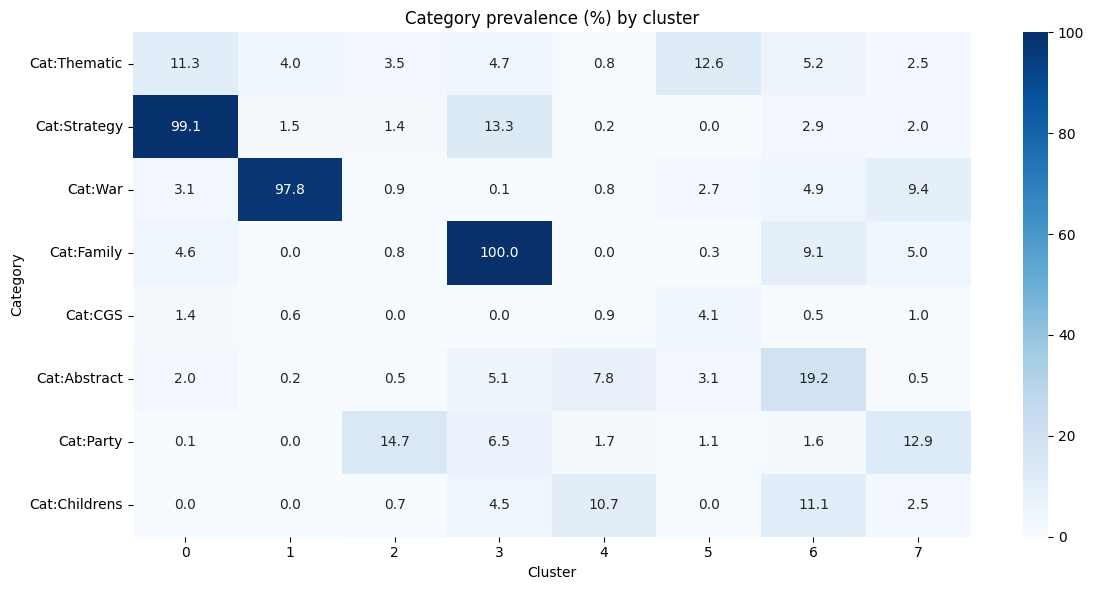

In [26]:
import seaborn as sns
import matplotlib.pyplot as plt



cluster_cat = dfc.groupby("cluster")[categoric_cols].mean() * 100

plt.figure(figsize=(12, 6))
sns.heatmap(
    cluster_cat.T.round(1),
    annot=True,
    fmt=".1f",
    cmap="Blues"
)
plt.title("Category prevalence (%) by cluster")
plt.xlabel("Cluster")
plt.ylabel("Category")
plt.tight_layout()
plt.show()



## PCA plot (post-clustering)


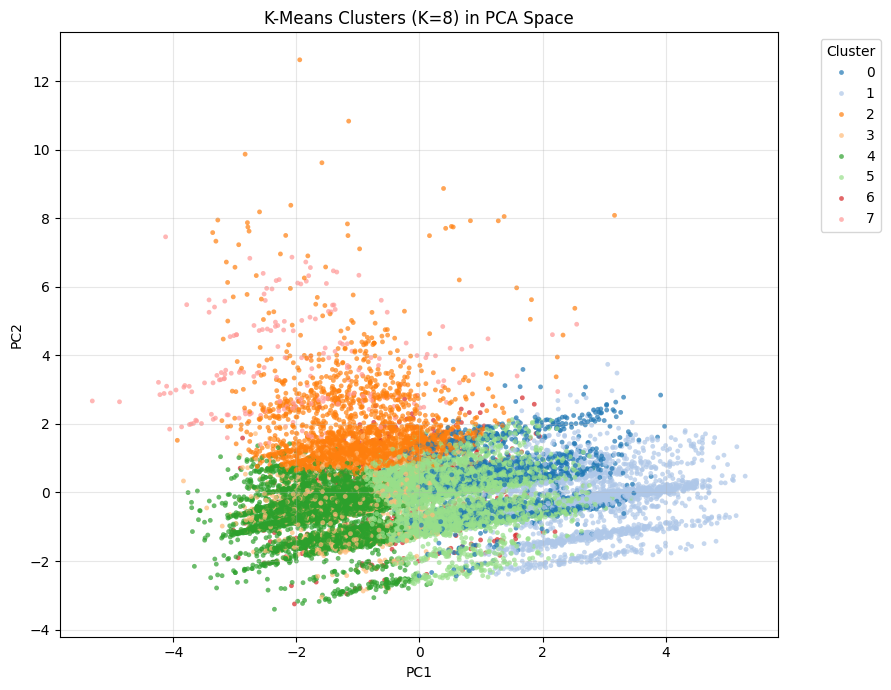

Explained variance by PC1 and PC2: [0.336 0.158]


In [27]:
from sklearn.decomposition import PCA

Xp = Xp[dfc.index]  # funziona se Xp è numpy array con stesso ordine di dfc

pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(Xp)

df_pca = dfc.copy()
df_pca["PC1"] = X_pca[:, 0]
df_pca["PC2"] = X_pca[:, 1]

palette = sns.color_palette("tab20", n_colors=df_pca["cluster"].nunique())

plt.figure(figsize=(9, 7))
sns.scatterplot(
    data=df_pca,
    x="PC1",
    y="PC2",
    hue="cluster",
    palette=palette,
    s=12,
    alpha=0.7,
    linewidth=0
)
plt.title("K-Means Clusters (K=8) in PCA Space")
plt.legend(title="Cluster", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("Explained variance by PC1 and PC2:",
      np.round(pca.explained_variance_ratio_, 3))


**The PCA visualization shows partial but not complete separation between clusters, which is expected given dimensionality reduction from 14 to 2 components.**

## Post-Clustering
This part is to analyze the question: how are Low / Medium / High rated games distributed across clusters? It allows us to see whether certain clusters are dominated by highly rated games or contain mostly low-rated ones.

The following graph shows percentages of Ratings across all clusters.

<Figure size 900x500 with 0 Axes>

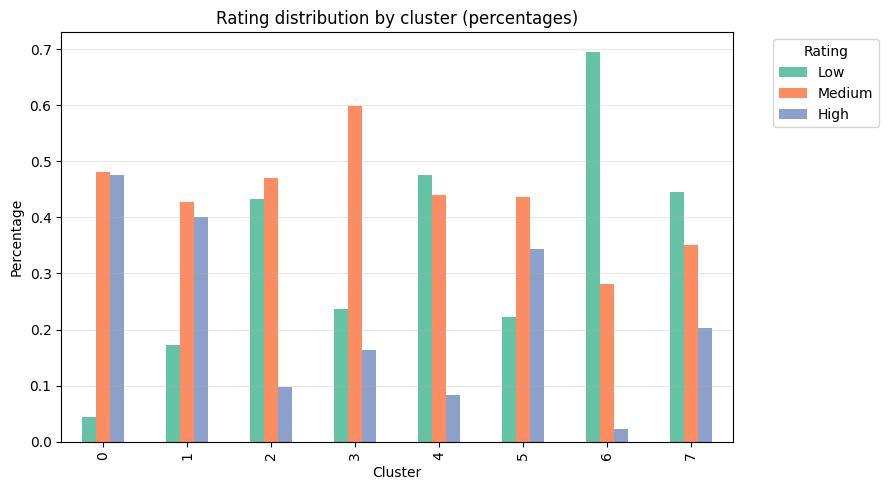

In [28]:
import seaborn as sns
import matplotlib.pyplot as plt

rating_proportions = (
    dfc.groupby("cluster")["Rating"]
       .value_counts(normalize=True)
       .unstack(fill_value=0)
       .round(3)
)

rating_order = ['Low', 'Medium', 'High']
rating_proportions = rating_proportions[[col for col in rating_order if col in rating_proportions.columns]]

plt.figure(figsize=(9, 5))

rating_proportions.plot(kind='bar', figsize=(9, 5), color=sns.color_palette("Set2"))
plt.title("Rating distribution by cluster (percentages)")
plt.xlabel("Cluster")
plt.ylabel("Percentage")
plt.legend(title="Rating", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()



The following graph shows average rating per cluster compared to the average.

In [2]:
import matplotlib.pyplot as plt

rating_map = {"Low": 1, "Medium": 2, "High": 3}

dfc["Rating_num"] = dfc["Rating"].map(rating_map)

mean_rating_per_cluster = (
    dfc.groupby("cluster")["Rating_num"]
       .mean()
       .round(3)
)

plt.figure(figsize=(8, 5))

# Calcola quali cluster sono sopra/sotto la media di 2
colors = ['steelblue' if x > 2 else 'coral' for x in mean_rating_per_cluster.values]
edge_colors = ['darkblue' if x > 2 else 'darkred' for x in mean_rating_per_cluster.values]

# Linee orizzontali - partono da 2 (la media)
for i, (idx, val) in enumerate(mean_rating_per_cluster.items()):
    if val > 2:
        # Sopra la media: va a destra
        plt.hlines(y=i, xmin=2, xmax=val, color='steelblue', alpha=0.6, linewidth=2.5)
    else:
        # Sotto la media: va a sinistra
        plt.hlines(y=i, xmin=val, xmax=2, color='coral', alpha=0.6, linewidth=2.5)

# Punti alla fine delle linee
plt.scatter(
    mean_rating_per_cluster.values, 
    range(len(mean_rating_per_cluster)), 
    s=150, 
    c=colors,
    edgecolors=edge_colors,
    linewidth=2,
    zorder=3
)

# Configurazione assi e labels
plt.yticks(range(len(mean_rating_per_cluster)), mean_rating_per_cluster.index)
plt.xlim(0.8, 3.2)
plt.xlabel("Mean Rating (1=Low, 3=High)")
plt.ylabel("Cluster")
plt.title("Average Rating Score per Cluster")

# Linea verticale per la media a 2
plt.axvline(x=2, color='gray', linestyle='--', alpha=0.7, linewidth=2, label='Average (2)')

plt.grid(axis="x", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

NameError: name 'df' is not defined

## Final Note
The rating-based analyses confirm that the clustering identifies distinct groups of board games that differ systematically in perceived quality. Even though ratings were excluded from the clustering process, they are a strong external validation signal, reinforcing the robustness and interpretability of the clustering results.

In [30]:
df_kmeans_export = dfc.copy()

df_kmeans_export[["BGGId", "cluster"]].to_csv(
    "kmeans_game_archetypes.csv",
    index=False
)
